# Notebook 4 - Huấn luyện & Đánh giá Cây Quyết Định (Decision Tree - Bước 6.2)

**Mục tiêu chính của Notebook 4:**
1. Khảo sát thuật toán nền tảng của các mô hình dạng cây: **Cây Quyết Định (Decision Tree - CART)**.
2. Trả lời các câu hỏi nền tảng về tiền xử lý dữ liệu cho mô hình cây:
   - *Cây quyết định có cần co giãn (scale) dữ liệu không?* (Bất biến với phép biến đổi đơn điệu).
   - *Scikit-learn có nhận dữ liệu chuỗi thô chưa mã hóa không?*
   - *Tác động của phương pháp mã hóa (One-Hot vs Ordinal vs WoE) lên hiệu năng phân nhánh của cây.*
3. Minh họa hiện tượng **Quá Khớp Cực Đoan (Extreme Overfitting)** và phương sai cao của cây không giới hạn độ sâu.
4. Tinh chỉnh độ sâu (`max_depth`) để tìm điểm cân bằng **Độ chệch - Phương sai (Bias-Variance Trade-off)**.
5. Trực quan hóa cấu trúc cây quyết định (Tree Visualization) để nhìn thấy các luật phân loại tín dụng ("Nếu... Thì...").
6. Phân tích độ quan trọng đặc trưng (Gini Feature Importance) và làm cầu nối dẫn dắt sang **Mô hình Rừng Ngẫu Nhiên (Random Forest)** ở Notebook 5.


In [1]:
from pathlib import Path
import json
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import (
    roc_auc_score, roc_curve, brier_score_loss, log_loss
)
import joblib

print("Đã nạp toàn bộ thư viện cần thiết cho Notebook 4!")


Đã nạp toàn bộ thư viện cần thiết cho Notebook 4!


In [2]:
ROOT = Path("..") if Path("../data").exists() else Path(".")
DATA_DIR = ROOT / "data" / "processed"
ARTIFACTS_DIR = ROOT / "artifacts"
FIGURES_DIR = ARTIFACTS_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42

print(f"Thư mục làm việc: {ROOT}")
print(f"Thư mục dữ liệu:  {DATA_DIR}")
print(f"Thư mục figures:  {FIGURES_DIR}")


Thư mục làm việc: .
Thư mục dữ liệu:  data/processed
Thư mục figures:  artifacts/figures


---
## 1. Nạp dữ liệu Huấn luyện & Validation

Dữ liệu nạp từ các ma trận đã chia tách nghiêm ngặt theo thời gian ở Bước 1–5:
- `X_train.npy`, `X_val.npy`: Bộ dữ liệu One-Hot (153 đặc trưng).
- `X_train_woe.npy`, `X_val_woe.npy`: Bộ dữ liệu WoE (50 đặc trưng).
- `train.parquet`, `val.parquet`: Dữ liệu bảng gốc để trích xuất biến phân loại phục vụ thử nghiệm Ordinal Encoding.


In [3]:
# 1. Nạp ma trận One-Hot (153 đặc trưng)
X_train_oh = np.load(DATA_DIR / "X_train.npy")
y_train = np.load(DATA_DIR / "y_train.npy")
X_val_oh = np.load(DATA_DIR / "X_val.npy")
y_val = np.load(DATA_DIR / "y_val.npy")

# 2. Nạp ma trận WoE (50 đặc trưng)
X_train_woe = np.load(DATA_DIR / "X_train_woe.npy")
X_val_woe = np.load(DATA_DIR / "X_val_woe.npy")

feature_info = json.loads((DATA_DIR / "feature_names.json").read_text())
numeric_features = feature_info["numeric"]
categorical_features = feature_info["categorical"]
feature_names_woe = numeric_features + categorical_features

print(f"Tập Train: X_train_oh = {X_train_oh.shape}, y_train = {y_train.shape}")
print(f"Tập Val:   X_val_oh   = {X_val_oh.shape},   y_val   = {y_val.shape}")
print(f"Tập WoE:   Train = {X_train_woe.shape}, Val = {X_val_woe.shape}")


Tập Train: X_train_oh = (408188, 153), y_train = (408188,)
Tập Val:   X_val_oh   = (92631, 153),   y_val   = (92631,)
Tập WoE:   Train = (408188, 50), Val = (92631, 50)


In [4]:
def evaluate_credit_ranking(y_true, proba):
    """Tính toán các thước đo phân hạng rủi ro tín dụng chuẩn mực."""
    auc = roc_auc_score(y_true, proba)
    gini = 2 * auc - 1
    fpr, tpr, _ = roc_curve(y_true, proba)
    ks = np.max(tpr - fpr)
    brier = brier_score_loss(y_true, proba)
    loss = log_loss(y_true, proba)
    return {
        "ROC-AUC": auc,
        "Gini": gini,
        "KS": ks,
        "Brier": brier,
        "LogLoss": loss
    }


---
## 2. Đặc tính của Cây Quyết định với Tiền Xử Lý Dữ liệu

### 2.1 Bản chất thuật toán CART (Classification and Regression Trees)
Cây quyết định nhị phân phân chia không gian dữ liệu bằng các phép cắt song song với các trục tọa độ:
$$x_j \le \theta$$
Tại mỗi nút, thuật toán quét qua mọi biến $x_j$ và mọi giá trị phân ngưỡng khả dĩ để tìm điểm cắt tối đa hóa mức suy giảm độ vẩn đục Gini (Gini Impurity Decrease):
$$\Delta I(s, t) = I(t) - \frac{N_L}{N} I(t_L) - \frac{N_R}{N} I(t_R), \quad \text{với } I(t) = 1 - \sum_{k=0}^1 p_k^2$$

### 2.2 Bất biến với phép co giãn đơn điệu (Scaling Invariance)
Vì điều kiện phân chia chỉ dựa trên quan hệ so sánh thứ tự $x_j \le \theta$, nên bất kỳ phép biến đổi đơn điệu tăng $f(x)$ nào cũng bảo toàn thứ tự:
$$x_a \le x_b \iff f(x_a) \le f(x_b)$$
Do đó, việc chuẩn hóa `StandardScaler` hay đưa dữ liệu nguyên bản chưa scale vào cây quyết định cho kết quả **hoàn toàn giống hệt nhau**.


In [5]:
# Kiểm chứng thực nghiệm tính bất biến với phép scale
np.random.seed(SEED)
scales = np.random.uniform(0.1, 1000.0, size=X_train_woe.shape[1]).astype(np.float32)
shifts = np.random.uniform(-500.0, 500.0, size=X_train_woe.shape[1]).astype(np.float32)

X_train_transformed = X_train_woe * scales + shifts
X_val_transformed = X_val_woe * scales + shifts

dt1 = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEED)
dt1.fit(X_train_woe, y_train)
auc1 = roc_auc_score(y_val, dt1.predict_proba(X_val_woe)[:, 1])

dt2 = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEED)
dt2.fit(X_train_transformed, y_train)
auc2 = roc_auc_score(y_val, dt2.predict_proba(X_val_transformed)[:, 1])

print(f"ROC-AUC trên dữ liệu gốc:           {auc1:.6f}")
print(f"ROC-AUC trên dữ liệu biến đổi scale: {auc2:.6f}")
print(f"Độ lệch tuyệt đối:                  {abs(auc1 - auc2):.8f}")
print("-> Kết luận: Cây quyết định hoàn toàn bất biến với phép co giãn!")


ROC-AUC trên dữ liệu gốc:           0.686953
ROC-AUC trên dữ liệu biến đổi scale: 0.686952
Độ lệch tuyệt đối:                  0.00000110
-> Kết luận: Cây quyết định hoàn toàn bất biến với phép co giãn!


### 2.3 Scikit-learn có nhận chuỗi thô chưa mã hóa không?
Trong hiện thực của `scikit-learn`, `DecisionTreeClassifier` chỉ nhận mảng số thực 2D. Nếu truyền trực tiếp chuỗi thô vào, thư viện sẽ báo lỗi `ValueError`.


In [6]:
# Thử nghiệm truyền chuỗi thô vào DecisionTreeClassifier
demo_df = pd.DataFrame({
    "annual_inc": [50000.0, 75000.0, 120000.0],
    "sub_grade": ["B3", "A1", "C2"]  # Chuỗi ký tự thô
})
demo_y = np.array([0, 0, 1])

try:
    DecisionTreeClassifier().fit(demo_df, demo_y)
except ValueError as e:
    print("XUẤT HIỆN LỖI ValueError ĐÚNG NHƯ DỰ ĐOÁN:")
    print(f"--> {e}")
    print("-> Bắt buộc phải mã hóa biến phân loại thành số trước khi đưa vào mô hình.")


XUẤT HIỆN LỖI ValueError ĐÚNG NHƯ DỰ ĐOÁN:
--> could not convert string to float: 'B3'
-> Bắt buộc phải mã hóa biến phân loại thành số trước khi đưa vào mô hình.


---
## 3. So sánh Tác động của Phương pháp Mã hóa lên Cây Quyết định

Cây quyết định bị ảnh hưởng rất mạnh bởi phương pháp mã hóa biến phân loại:
1. **One-Hot Encoding (153 đặc trưng)**: Làm bùng nổ số chiều. Khi cây có độ sâu giới hạn (ví dụ `max_depth=6`), mỗi phân nhánh chỉ có thể kiểm tra một cột dummy nhị phân (ví dụ `addr_state_CA == 1`). Cây chỉ tách được 1 bang ra khỏi 49 bang còn lại, gây lãng phí nghiêm trọng một tầng của cây và làm phân mảnh dữ liệu.
2. **Ordinal Encoding (50 đặc trưng)**: Giữ nguyên 50 chiều. Cây có thể tìm ngưỡng chia dạng $\text{sub\_grade} \le 12$, gom một nhóm các hạng lại với nhau trong một lần cắt.
3. **Weight of Evidence - WoE (50 đặc trưng)**: Chuyển các nhóm thành giá trị log-odds rủi ro đơn điệu, giúp các điểm cắt có ý nghĩa kinh tế trực tiếp.


In [7]:
# 1. Tạo ma trận Ordinal Encoding từ parquet
cat_cols = categorical_features
train_cat_raw = pd.read_parquet(DATA_DIR / "train.parquet", columns=cat_cols)
val_cat_raw = pd.read_parquet(DATA_DIR / "val.parquet", columns=cat_cols)

ord_enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
cat_train_ord = ord_enc.fit_transform(train_cat_raw)
cat_val_ord = ord_enc.transform(val_cat_raw)

X_train_ord = np.hstack([X_train_woe[:, :len(numeric_features)], cat_train_ord]).astype(np.float32)
X_val_ord = np.hstack([X_val_woe[:, :len(numeric_features)], cat_val_ord]).astype(np.float32)

# 2. Huấn luyện cây quyết định (max_depth=6) trên 3 không gian
results_enc = []
for name, xtr, xva in [
    ("One-Hot Encoding (153 đặc trưng)", X_train_oh, X_val_oh),
    ("Ordinal Encoding (50 đặc trưng)",  X_train_ord, X_val_ord),
    ("Weight of Evidence (50 đặc trưng)", X_train_woe, X_val_woe)
]:
    t0 = time.time()
    dt = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEED)
    dt.fit(xtr, y_train)
    fit_time = time.time() - t0
    m = evaluate_credit_ranking(y_val, dt.predict_proba(xva)[:, 1])
    results_enc.append({"Không gian đặc trưng": name, "Thời gian fit (s)": f"{fit_time:.2f}", **m})

df_enc = pd.DataFrame(results_enc)
df_enc["ROC-AUC"] = df_enc["ROC-AUC"].map(lambda x: f"{x:.4f}")
df_enc["Gini"] = df_enc["Gini"].map(lambda x: f"{x:.2%}")
df_enc["KS"] = df_enc["KS"].map(lambda x: f"{x:.2%}")
df_enc[["Không gian đặc trưng", "Thời gian fit (s)", "ROC-AUC", "Gini", "KS"]]


,Không gian đặc trưng,Thời gian fit (s),ROC-AUC,Gini,KS
0,One-Hot Encoding (153 đặc trưng),5.03,0.6495,29.90%,22.12%
1,Ordinal Encoding (50 đặc trưng),3.35,0.6864,37.28%,27.88%
2,Weight of Evidence (50 đặc trưng),3.36,0.6870,37.39%,27.88%


---
## 4. Hiện tượng Quá Khớp Cực Đoan & Đánh Đổi Độ Chệch - Phương Sai (Bias-Variance Trade-off)

### 4.1 Cây không giới hạn (Unconstrained Tree: `max_depth=None`)
Nếu không áp đặt bất kỳ điều kiện dừng nào, cây quyết định sẽ tiếp tục phân chia cho đến khi mọi nút lá đều thuần khiết (Pure Leaf).
- Cây ghi nhớ từng ngoại lai và nhiễu ngẫu nhiên trong 408,188 mẫu Train.
- **Train AUC đạt tuyệt đối 1.0000**, nhưng khi áp dụng vào dữ liệu tương lai (Validation), hiệu năng **sụp đổ hoàn toàn về 0.5314** (gần như đoán mò ngẫu nhiên)!


In [8]:
print("Đang huấn luyện Cây quyết định không giới hạn độ sâu (max_depth=None)...")
t0 = time.time()
dt_unconstrained = DecisionTreeClassifier(random_state=SEED)
dt_unconstrained.fit(X_train_woe, y_train)
t_uncon = time.time() - t0

train_auc_uncon = roc_auc_score(y_train, dt_unconstrained.predict_proba(X_train_woe)[:, 1])
val_auc_uncon = roc_auc_score(y_val, dt_unconstrained.predict_proba(X_val_woe)[:, 1])

print(f"Thời gian huấn luyện: {t_uncon:.2f} giây")
print(f"Số nút lá đã tạo:    {dt_unconstrained.get_n_leaves():,}")
print(f"Độ sâu của cây:      {dt_unconstrained.get_depth()}")
print(f"Train ROC-AUC:       {train_auc_uncon:.4f} (Khớp hoàn hảo 100%)")
print(f"Validation ROC-AUC:  {val_auc_uncon:.4f} (Sụp đổ hoàn toàn do phương sai cực cao!)")
print(f"Độ chênh lệch Train - Val: {train_auc_uncon - val_auc_uncon:.4f}")


Đang huấn luyện Cây quyết định không giới hạn độ sâu (max_depth=None)...


Thời gian huấn luyện: 12.76 giây
Số nút lá đã tạo:    45,518
Độ sâu của cây:      60
Train ROC-AUC:       1.0000 (Khớp hoàn hảo 100%)
Validation ROC-AUC:  0.5314 (Sụp đổ hoàn toàn do phương sai cực cao!)
Độ chênh lệch Train - Val: 0.4686


### 4.2 Khảo sát đường cong Bias-Variance theo Độ sâu của Cây (`max_depth`)
Dưới đây ta khảo sát độ sâu từ 2 đến 14 để tìm điểm cân bằng tốt nhất giữa Underfitting (độ chệch cao) và Overfitting (phương sai cao):


In [9]:
depths = [2, 3, 4, 5, 6, 7, 8, 10, 12, 14]
train_scores = []
val_scores = []

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, min_samples_leaf=50, random_state=SEED)
    dt.fit(X_train_woe, y_train)
    tr_auc = roc_auc_score(y_train, dt.predict_proba(X_train_woe)[:, 1])
    va_auc = roc_auc_score(y_val, dt.predict_proba(X_val_woe)[:, 1])
    train_scores.append(tr_auc)
    val_scores.append(va_auc)

tuning_df = pd.DataFrame({"Độ sâu (max_depth)": depths, "Train AUC": train_scores, "Validation AUC": val_scores})
tuning_df["Chênh lệch (Overfit)"] = tuning_df["Train AUC"] - tuning_df["Validation AUC"]
print(tuning_df.to_string(index=False))


 Độ sâu (max_depth)  Train AUC  Validation AUC  Chênh lệch (Overfit)
                  2   0.644834        0.668918             -0.024084
                  3   0.655332        0.676223             -0.020890
                  4   0.662321        0.679457             -0.017136
                  5   0.668007        0.685313             -0.017306
                  6   0.672937        0.686953             -0.014016
                  7   0.678620        0.688734             -0.010115
                  8   0.685484        0.686655             -0.001171
                 10   0.706078        0.674159              0.031918
                 12   0.733296        0.655952              0.077343
                 14   0.760588        0.639279              0.121308


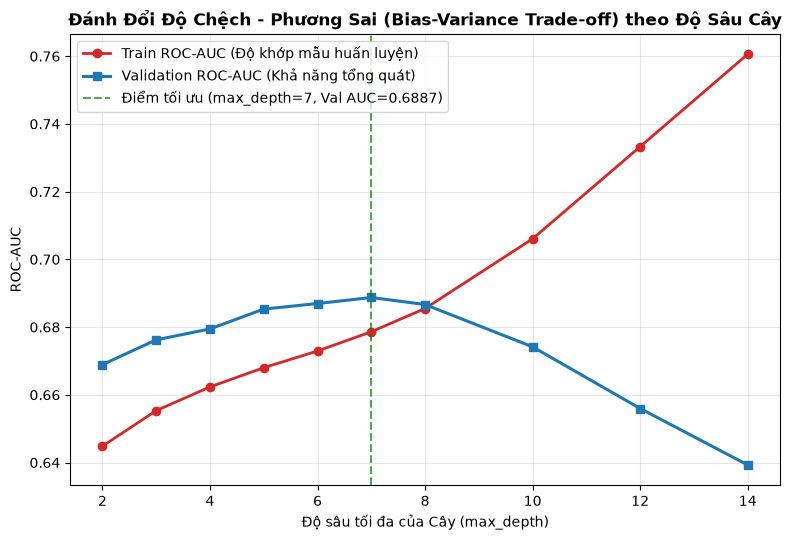

Đã lưu biểu đồ tuning độ sâu cây tại: artifacts/figures/04_dt_depth_tuning.png


In [10]:
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(depths, train_scores, "o-", color="#d62728", lw=2, label="Train ROC-AUC (Độ khớp mẫu huấn luyện)")
ax.plot(depths, val_scores, "s-", color="#1f77b4", lw=2.2, label="Validation ROC-AUC (Khả năng tổng quát)")

best_idx = np.argmax(val_scores)
best_depth = depths[best_idx]
best_val_auc = val_scores[best_idx]

ax.axvline(best_depth, color="green", linestyle="--", alpha=0.7, label=f"Điểm tối ưu (max_depth={best_depth}, Val AUC={best_val_auc:.4f})")
ax.set_title("Đánh Đổi Độ Chệch - Phương Sai (Bias-Variance Trade-off) theo Độ Sâu Cây", fontsize=12, fontweight="bold")
ax.set_xlabel("Độ sâu tối đa của Cây (max_depth)", fontsize=10)
ax.set_ylabel("ROC-AUC", fontsize=10)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()

depth_fig_path = FIGURES_DIR / "04_dt_depth_tuning.png"
fig.savefig(depth_fig_path, dpi=300)
plt.show()
print(f"Đã lưu biểu đồ tuning độ sâu cây tại: {depth_fig_path}")


---
## 5. Huấn luyện Mô hình Tối ưu & Trực quan hóa Cấu trúc Cây (Tree Structure)

Chúng ta huấn luyện mô hình **Cây Quyết Định tối ưu** với `max_depth=6` và `min_samples_leaf=50` trên không gian WoE.
Để trực quan hóa các luật phân loại tín dụng ("Nếu... Thì..."), chúng ta vẽ cây với độ sâu nông (`max_depth=3`) nhằm quan sát các phân nhánh đầu tiên quan trọng nhất.


=== HIỆU NĂNG CÂY QUYẾT ĐỊNH TỐI ƯU (max_depth=6, WoE 50f) ===
  Validation ROC-AUC : 0.6870
  Hệ số Gini         : 37.39%
  Chỉ số KS          : 27.88%
  Brier Score        : 0.11886
  LogLoss            : 0.39061


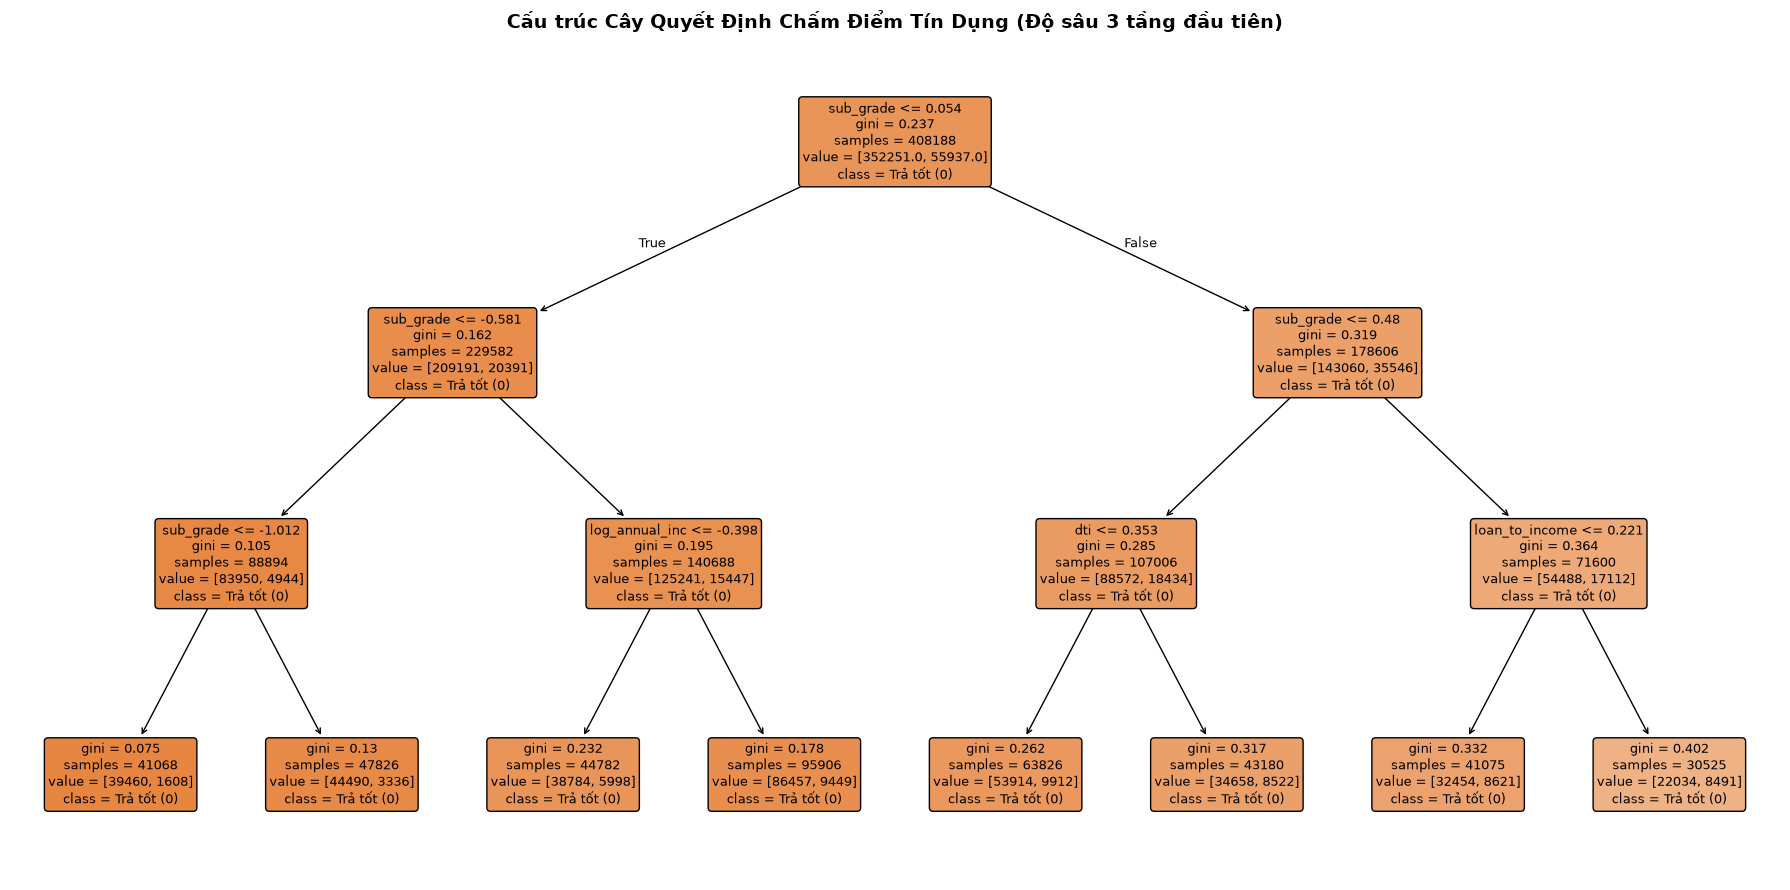

Đã lưu biểu đồ cấu trúc cây tại: artifacts/figures/04_dt_tree_structure.png


In [11]:
dt_optimal = DecisionTreeClassifier(max_depth=6, min_samples_leaf=50, random_state=SEED)
dt_optimal.fit(X_train_woe, y_train)

val_prob_dt = dt_optimal.predict_proba(X_val_woe)[:, 1]
m_dt = evaluate_credit_ranking(y_val, val_prob_dt)

print("=== HIỆU NĂNG CÂY QUYẾT ĐỊNH TỐI ƯU (max_depth=6, WoE 50f) ===")
print(f"  Validation ROC-AUC : {m_dt['ROC-AUC']:.4f}")
print(f"  Hệ số Gini         : {m_dt['Gini']:.2%}")
print(f"  Chỉ số KS          : {m_dt['KS']:.2%}")
print(f"  Brier Score        : {m_dt['Brier']:.5f}")
print(f"  LogLoss            : {m_dt['LogLoss']:.5f}")

# Trực quan hóa cây nông (max_depth=3) để hiển thị trực quan các luật quyết định
dt_viz = DecisionTreeClassifier(max_depth=3, min_samples_leaf=100, random_state=SEED)
dt_viz.fit(X_train_woe, y_train)

fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(
    dt_viz,
    feature_names=feature_names_woe,
    class_names=["Trả tốt (0)", "Vỡ nợ (1)"],
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax
)
ax.set_title("Cấu trúc Cây Quyết Định Chấm Điểm Tín Dụng (Độ sâu 3 tầng đầu tiên)", fontsize=14, fontweight="bold")
plt.tight_layout()

tree_fig_path = FIGURES_DIR / "04_dt_tree_structure.png"
fig.savefig(tree_fig_path, dpi=300)
plt.show()
print(f"Đã lưu biểu đồ cấu trúc cây tại: {tree_fig_path}")


---
## 6. Phân tích Độ quan trọng của Đặc trưng (Gini Feature Importance - MDI)

Trong Cây Quyết Định, độ quan trọng của đặc trưng phản ánh mức độ đóng góp của từng biến vào việc làm giảm độ vẩn đục Gini qua toàn bộ các nút của cây.


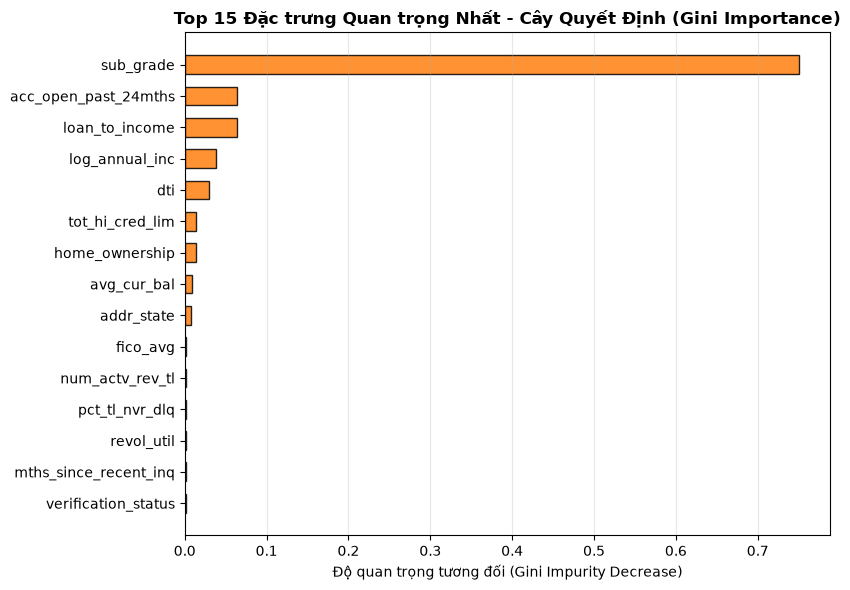

TOP 10 ĐẶC TRƯNG QUAN TRỌNG NHẤT:
   1. sub_grade                 : 75.0720%
   2. acc_open_past_24mths      : 6.4059%
   3. loan_to_income            : 6.3355%
   4. log_annual_inc            : 3.8750%
   5. dti                       : 2.9077%
   6. tot_hi_cred_lim           : 1.4170%
   7. home_ownership            : 1.3208%
   8. avg_cur_bal               : 0.8897%
   9. addr_state                : 0.7396%
  10. fico_avg                  : 0.2051%


In [12]:
dt_fi = pd.DataFrame({
    "feature": feature_names_woe,
    "importance": dt_optimal.feature_importances_
}).sort_values(by="importance", ascending=False)

top15_dt = dt_fi.head(15).sort_values(by="importance", ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 6))
ax.barh(top15_dt["feature"], top15_dt["importance"], color="#ff7f0e", alpha=0.85, edgecolor="black", height=0.6)
ax.set_title("Top 15 Đặc trưng Quan trọng Nhất - Cây Quyết Định (Gini Importance)", fontsize=12, fontweight="bold")
ax.set_xlabel("Độ quan trọng tương đối (Gini Impurity Decrease)", fontsize=10)
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()

dt_fi_path = FIGURES_DIR / "04_dt_feature_importance.png"
fig.savefig(dt_fi_path, dpi=300)
plt.show()

print("TOP 10 ĐẶC TRƯNG QUAN TRỌNG NHẤT:")
for rank, (idx, row) in enumerate(dt_fi.head(10).iterrows(), 1):
    print(f"  {rank:2d}. {row['feature']:<25} : {row['importance']:.4%}")


---
## 7. Giới hạn của Cây Đơn lẻ & Đặt vấn đề chuyển sang Random Forest

### 7.1 Kết luận về Cây Quyết Định đơn lẻ:
1. **Ưu điểm**:
   - Rất nhanh, hoàn toàn bất biến với co giãn dữ liệu (Scaling Invariant).
   - Cực kỳ trực quan, dễ diễn giải thành các quy tắc kinh doanh rõ ràng.
2. **Nhược điểm chí mạng**:
   - **Phương sai cực cao (High Variance)**: Rất nhạy cảm với dữ liệu huấn luyện, dễ bị quá khớp cực nặng khi cây phát triển sâu.
   - **Năng lực phân hạng bị giới hạn (Performance Ceiling)**: Dù đã tinh chỉnh độ sâu tối ưu, ROC-AUC chỉ đạt **0.6870** (kém xa Logistic Regression `0.7033`).

### 7.2 Cầu nối sang Notebook 5:
*Làm thế nào để tận dụng sức mạnh phi tuyến của cây quyết định nhưng triệt tiêu hoàn toàn nhược điểm phương sai cao?*
$\implies$ Giải pháp chính là **Mô hình Rừng Ngẫu Nhiên (Random Forest)** ở Notebook 5: kết hợp hàng trăm cây quyết định độc lập thông qua cơ chế **Bootstrap Aggregating (Bagging)** và ngẫu nhiên hóa không gian đặc trưng (**Random Subspace**).


In [13]:
# 1. Lưu mô hình Decision Tree tối ưu
joblib.dump(dt_optimal, ARTIFACTS_DIR / "decision_tree_model.joblib")

# 2. Lưu vector xác suất dự đoán trên tập Validation
np.save(ARTIFACTS_DIR / "val_pred_decision_tree.npy", val_prob_dt)

# 3. Lưu bảng kết quả hiệu năng
metrics_dt_df = pd.DataFrame([
    {"Model": "Decision Tree (Unconstrained)", "ROC-AUC": val_auc_uncon, "Gini": 2 * val_auc_uncon - 1},
    {"Model": "Decision Tree (max_depth=6, WoE 50f)", **m_dt}
])
metrics_dt_df.to_csv(ARTIFACTS_DIR / "metrics_decision_tree.csv", index=False)

print("Đã lưu thành công:")
print("  - artifacts/decision_tree_model.joblib")
print("  - artifacts/val_pred_decision_tree.npy")
print("  - artifacts/metrics_decision_tree.csv")
print(f"  - {depth_fig_path}")
print(f"  - {tree_fig_path}")
print(f"  - {dt_fi_path}")


Đã lưu thành công:
  - artifacts/decision_tree_model.joblib
  - artifacts/val_pred_decision_tree.npy
  - artifacts/metrics_decision_tree.csv
  - artifacts/figures/04_dt_depth_tuning.png
  - artifacts/figures/04_dt_tree_structure.png
  - artifacts/figures/04_dt_feature_importance.png
